In [98]:
#run this twice to get rid of scary warning text :/
import marvin
from marvin.tools import Cube
from marvin.tools import Maps
from marvin.tools.vacs import VACs
from marvin import config
import sdss_access
config.setRelease("DR17")
config.mode = 'remote'
config.download = True
print("Release:", config.release)
print("Mode:", config.mode)
import astropy as astro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Release: DR17
Mode: remote


In [99]:
VACs()
#OK so this should have had VAC visual_morphology
#...apparently though it is hidden from public access but still available if you know where to look lol

<VACs (firefly, galaxyzoo, gz3d, gema, HI)>

In [120]:
catalog = "manga_visual_morpho-2.0.1.fits" #read in visual_morphology VAC
Table = astro.table.Table.read(catalog)
Table = Table.to_pandas() #pandas is better than astropy tables imo
# np.unique(Table['Type'])

Whitelist = ['S0', 'SAB0', 'SB0', 'S0a', 'SAB0a', 'SB0a'] #these are the Hubble types I want to focus on

#Now we make a table based on that whitelist. Theres some weird formatting stuff too so b'SB0 ' becomes just SB0
BetterTable = Table[Table['Type'].str.decode('utf-8').str.strip().isin(Whitelist)].copy() 
BetterTable['Type'] = (BetterTable['Type'].str.decode('utf-8').str.strip())
BetterTable['Name'] = (BetterTable['Name'].str.decode('utf-8').str.strip())
BetterTable['plateifu'] = (BetterTable['plateifu'].str.decode('utf-8').str.strip())
BetterTable['MANGAID'] = (BetterTable['MANGAID'].str.decode('utf-8').str.strip())

#Some 2000 Galaxies. Now I focus on non-edge on galaxies. I want face on to make maps with
BetterTable = BetterTable[BetterTable['Edge_on'] == 0].copy()
#209 left. This should be pretty good, but I want to better check inclination
#To do this, I want to use axis ratios. Let's get that data
drpall = "drpall-v3_1_1.fits" #found this file had axis ratios
drpallTable = astro.table.Table.read(drpall, hdu=1)
axis_ratios = drpallTable[["mangaid", "nsa_elpetro_ba", "nsa_sersic_ba"]].to_pandas()
axis_ratios['mangaid'] = (axis_ratios['mangaid'].str.decode('utf-8').str.strip())
axis_ratios = axis_ratios.drop_duplicates(subset="mangaid")

#merge tables
BetterTable = BetterTable.merge(axis_ratios, left_on="MANGAID", right_on="mangaid", how="left", validate="many_to_one")
BetterTable = BetterTable.drop(columns = 'mangaid')

#Let's now make some "inclination" cut
BetterTable = BetterTable[BetterTable['nsa_elpetro_ba'] >= 0.95]

#TODO filter out tidal ones, these look probably fine in most cases but I have enough I can remove easily still

In [122]:
BetterTable

,Name,plateifu,MANGAID,objra,objdec,Type,TType,Unsure,Bars,Edge_on,Tidal,C,E_C,A,E_A,S,E_S,cas_flag,nsa_elpetro_ba,nsa_sersic_ba
5,manga-10213-3701,10213-3701,1-72733,122.867048,43.638345,S0,-2,0,0.00,0,1,3.754,0.330,0.124,0.018,0.23,0.2330,1,0.955200,0.935950
28,manga-10220-3702,10220-3702,1-201956,120.436461,31.838364,S0a,0,0,0.00,0,0,3.041,0.358,0.097,0.005,0.10,0.1035,1,0.992717,0.959941
38,manga-10492-1902,10492-1902,1-380333,123.686549,58.279847,SAB0a,0,0,0.50,0,0,3.660,0.408,0.055,0.002,0.16,0.0795,1,0.965349,0.945740
40,manga-10492-6104,10492-6104,1-380032,122.985124,56.979007,SB0a,0,0,0.75,0,0,4.431,0.253,0.088,0.005,0.03,0.0550,1,0.976911,0.941372
121,manga-10516-3701,10516-3701,1-60689,150.955434,2.271354,S0a,0,0,0.00,0,0,3.017,0.388,0.099,0.007,0.11,0.1255,1,0.965302,0.909388
173,manga-11007-3702,11007-3702,1-456332,194.485486,27.382313,S0,-2,0,0.00,0,1,2.933,0.289,0.099,0.023,-0.08,0.1850,1,0.968486,0.978367
257,manga-11753-9101,11753-9101,1-55194,146.151861,2.400868,S0a,0,0,0.00,0,1,3.637,0.281,0.080,0.011,0.01,0.0530,1,0.991832,0.977418
295,manga-11830-3701,11830-3701,1-233983,197.268791,49.766435,S0,-2,0,0.00,0,0,4.809,0.133,0.372,0.023,0.02,0.0835,1,0.956475,0.920289
312,manga-11835-6102,11835-6102,1-70077,219.008411,2.851625,S0a,0,0,0.00,0,0,4.406,0.250,0.053,0.008,0.05,0.1330,1,0.956979,0.946149
315,manga-11838-1902,11838-1902,1-609044,156.727477,-0.541518,S0,-2,0,0.00,0,1,3.742,0.329,0.092,0.003,0.08,0.1260,1,0.986338,0.983225


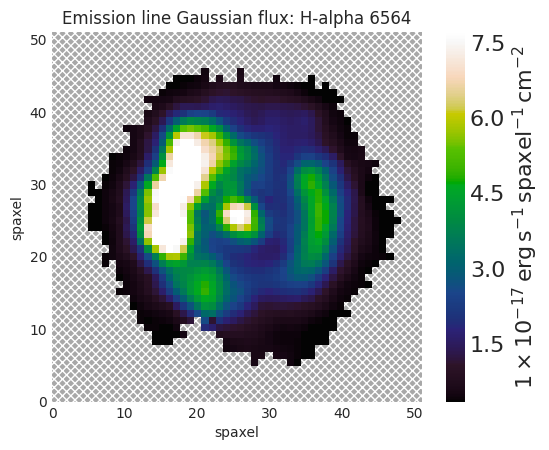

In [117]:
my_cube = marvin.tools.Maps('9886-6103')
ha = my_cube.emline_gflux_ha_6564
fig, ax = ha.plot()

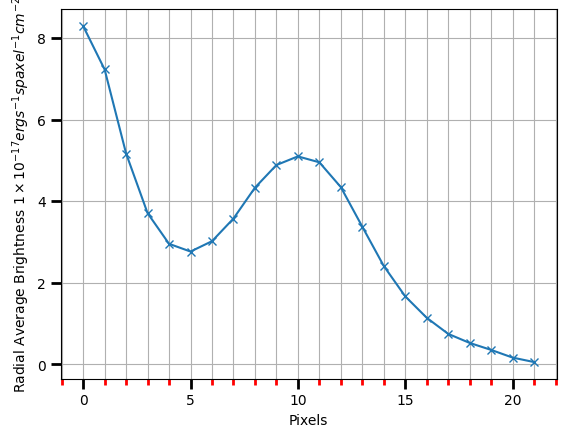

In [151]:
#Radial Porfile adapted from https://stackoverflow.com/a/34979185
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

minorLocator = AutoMinorLocator()


def radial_profile(data, center):
    x, y = np.indices((data.shape))
    r = np.sqrt((x - center[0])**2 + (y - center[1])**2)
    r = r.astype(int)

    tbin = np.bincount(r.ravel(), data.ravel())
    nr = np.bincount(r.ravel())
    radialprofile = tbin / nr
    return radialprofile 


# fitsFile = fits.open('testfig.fits')
img = np.array(ha)
img[np.isnan(img)] = 0

#center = np.unravel_index(img.argmax(), img.shape)
center = (26, 26) #half of 52, which is the spaxel grid shape as seen in the maps
rad_profile = radial_profile(img, center)

fig, ax = plt.subplots()
plt.plot(rad_profile[0:22], 'x-')

ax.xaxis.set_minor_locator(minorLocator)

plt.tick_params(which='both', width=2)
plt.tick_params(which='major', length=7)
plt.tick_params(which='minor', length=4, color='r')
plt.grid()
# ax.set_ylabelr('Radial Average Brightness $(1E-17 erg s^-1 spaxel^-1 cm^-2)$')
ax.set_ylabel(r'Radial Average Brightness $1 \times 10^{-17} erg s^{-1} spaxel^{-1} cm^{-2}$')
ax.set_xlabel("Pixels")
plt.grid(which="minor")
plt.show()
